SUODATUKSIA-tehtävä

ladataan lähtökuva f ja määrätään sille koko 100x100

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt


im = Image.open('/home/jankkuaho/Pictures/Screenshots/kalastus.jpeg')
f = np.asarray(im.convert('L').resize((100, 100)), dtype=float)




suodattimen w kertoimet. Keskus 4 saa suurimman painon.

In [ ]:

w = np.array([[1, 2, 1],
              [2, 4, 2],
              [1, 3, 1]]) / 16.0

Suodatetaan käyttäen samaa laskutyyliä kuin käsin

In [ ]:

def suodata(f, w):
    wr, wc = w.shape
    g = np.zeros((f.shape[0]-wr+1, f.shape[1]-wc+1))
    for x in range(g.shape[0]):
        for y in range(g.shape[1]):
            g[x, y] = (w * f[x:x+wr, y:y+wc]).sum()
    return g

Lasketaan tasoitus suodattamalla kuva ytimellä ja lasketaan myös high-boost vähentämällä tasoitusta alkuperäisestä, ja lisäämällä se takaisin vahvistettuna.

In [ ]:

taso = suodata(f, w)


fc = f[:98, :98]              
detail = fc - taso
boost = fc + 1.0 * detail  

Näytetään vierekkäin f, w smoothing ja w high-boost kuvat

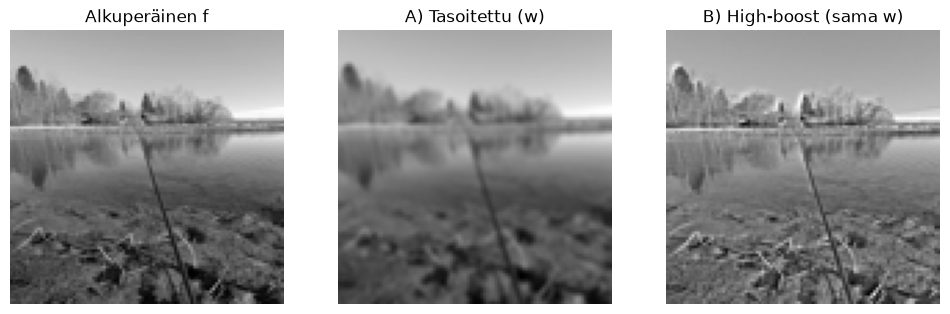

In [ ]:

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(f,    cmap='gray'); ax[0].set_title('Alkuperäinen f')
ax[1].imshow(taso, cmap='gray'); ax[1].set_title('A) Tasoitettu (w)')
ax[2].imshow(boost,cmap='gray'); ax[2].set_title('B) High-boost (sama w)')
for a in ax: a.axis('off')
plt.show()